# Efficient frontier

Efficient frontier for the complete working example in `mvo_examples.pdf`: the same simulated data (seed 42, 30 stocks, 500 days), Ledoit-Wolf covariance and SLSQP mean-variance solver. The figure is also saved to `efficient_frontier.pdf`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import minimize
from sklearn.covariance import LedoitWolf

%matplotlib inline

## 1. Simulate 30 stocks, 500 days

In [2]:
np.random.seed(42)

N, T = 30, 500
market = np.random.normal(0.0004, 0.012, T)
returns = np.column_stack([
    np.random.uniform(0.5, 1.5) * market
    + np.random.normal(0, np.random.uniform(0.008, 0.02), T)
    for _ in range(N)
])

mu = returns.mean(axis=0) * 252
cov_lw = LedoitWolf().fit(returns).covariance_ * 252

## 2. Risk-return trade-off MVO

$$\max_{\mathbf w}\ \mathbf w^T\boldsymbol\mu-\lambda\,\mathbf w^T\boldsymbol\Sigma\mathbf w\quad\text{s.t. } \mathbf w^T\mathbf 1=1,\ w_i\ge 0$$

In [3]:
def mvo(mu, cov, lam):
    N = len(mu)
    result = minimize(lambda w: -(w @ mu - lam * w @ cov @ w),
                      np.ones(N) / N, method='SLSQP',
                      bounds=[(0, 1)] * N,
                      constraints=[{'type': 'eq',
                                    'fun': lambda w: w.sum() - 1}])
    return result.x


def portfolio_stats(w, mu, cov):
    ret = w @ mu
    vol = np.sqrt(w @ cov @ w)
    return ret, vol, ret / vol

## 3. Frontier and reference portfolios

In [4]:
lambdas = np.logspace(-1, 3, 30)
frontier = [mvo(mu, cov_lw, lam) for lam in lambdas]
stats = np.array([portfolio_stats(w, mu, cov_lw) for w in frontier])
f_ret, f_vol, f_sharpe = stats.T

w_mv = mvo(mu, cov_lw, lam=1e4)               # lambda -> infinity: min variance
w_ms = frontier[int(np.argmax(f_sharpe))]     # best Sharpe on the lambda grid
w_mvo = mvo(mu, cov_lw, lam=5)                # moderate risk aversion
w_eq = np.ones(N) / N
vols = np.sqrt(np.diag(cov_lw))
w_iv = (1 / vols) / np.sum(1 / vols)

portfolios = {'Min variance': w_mv, 'Max Sharpe': w_ms, 'MVO (lambda=5)': w_mvo,
              'Equal weight': w_eq, 'Inverse vol': w_iv}
for name, w in portfolios.items():
    r, v, s = portfolio_stats(w, mu, cov_lw)
    print(f"{name:15s}  Ret={r:6.2%}  Vol={v:6.2%}  Sharpe={s:.2f}  Holdings={np.sum(w > 1e-4)}")

Min variance     Ret= 4.89%  Vol=12.00%  Sharpe=0.41  Holdings=13
Max Sharpe       Ret=45.87%  Vol=19.81%  Sharpe=2.32  Holdings=6
MVO (lambda=5)   Ret=48.93%  Vol=21.15%  Sharpe=2.31  Holdings=5
Equal weight     Ret=12.18%  Vol=16.68%  Sharpe=0.73  Holdings=30
Inverse vol      Ret=10.95%  Vol=15.93%  Sharpe=0.69  Holdings=30


## 4. Plot

Colour-blind-safe palette (no red/green).

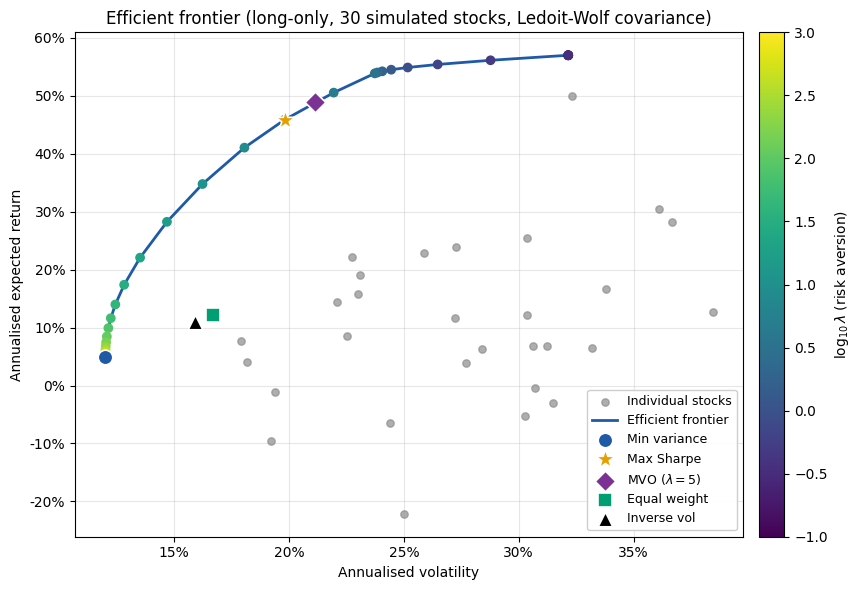

In [5]:
blue, orange, purple, teal, grey = "#1f5aa6", "#e69f00", "#7b3294", "#009e73", "#8c8c8c"

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(vols, mu, s=28, color=grey, alpha=0.7, label="Individual stocks", zorder=2)
sc = ax.scatter(f_vol, f_ret, c=np.log10(lambdas), cmap="viridis", s=36, zorder=4)
ax.plot(f_vol, f_ret, color=blue, lw=2, zorder=3, label="Efficient frontier")

points = [
    ("Min variance", w_mv, "o", blue),
    ("Max Sharpe", w_ms, "*", orange),
    (r"MVO ($\lambda=5$)", w_mvo, "D", purple),
    ("Equal weight", w_eq, "s", teal),
    ("Inverse vol", w_iv, "^", "black"),
]
for name, w, marker, colour in points:
    r, v, _ = portfolio_stats(w, mu, cov_lw)
    ax.scatter(v, r, marker=marker, s=220 if marker == "*" else 110, color=colour,
               edgecolor="white", linewidth=1.2, zorder=6, label=name)

cbar = fig.colorbar(sc, ax=ax, pad=0.02)
cbar.set_label(r"$\log_{10}\lambda$ (risk aversion)")

ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.set_xlabel("Annualised volatility")
ax.set_ylabel("Annualised expected return")
ax.set_title("Efficient frontier (long-only, 30 simulated stocks, Ledoit-Wolf covariance)")
ax.grid(alpha=0.3)
ax.legend(loc="lower right", fontsize=9, framealpha=0.95)
fig.tight_layout()

fig.savefig(Path.cwd() / "efficient_frontier.pdf")
plt.show()